Libraries

In [272]:
# import basic libraries
import os
from glob import glob

from pathlib import Path
import pandas as pd 
import matplotlib.pyplot as plt
from PIL import Image

import numpy as np

In [273]:
# import data augmentation
import imgaug as ia
from imgaug import augmenters as iaa
# import segmentation maps from imgaug
from imgaug.augmentables.segmaps import SegmentationMapOnImage
import imgaug.imgaug

Load data

In [274]:
# set paths to train and test image datasets

train_path = '../data/raw/train_images/'
test_path = '../data/raw//test_images/'

In [275]:
# load dataframe with train labels

train_df = pd.read_csv(r"../data/raw/train.csv/train.csv")
train_df.head(15)

,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...
5,002be4f.jpg_Flower,100850 142 101234 142 101618 142 102002 142 10...
6,002be4f.jpg_Gravel,NaN
7,002be4f.jpg_Sugar,5074 96 5458 96 5842 96 6226 96 6610 96 6994 9...
8,0031ae9.jpg_Fish,579 190 963 190 1347 190 1731 190 2115 190 249...
9,0031ae9.jpg_Flower,178 193 562 193 946 193 1330 193 1714 193 2098...


In [276]:
train_df.shape

(22184, 2)

In [277]:
# 1. Number of rows
print("Number of rows in train_df is:", len(train_df))

Number of rows in train_df is: 22184


In [278]:
# 2. Type of each variable
print("Variable types:\n")
print(train_df.dtypes)

Variable types:

Image_Label      str
EncodedPixels    str
dtype: object


##### 3. Description of the table's columns

"Image_Label": "Image ID and format combined with the cloud class.",

"EncodedPixels": "Encoded cloud mask. It contains the index number of the starting pixel masked as cloud and also the number of themcloudy pixels. For example "20056 257" means that the index of the starting cloud pixel is 20056 and by next 57 pixels are encoded as cloudy pixel in the format of fish. 
Moreover, NaN value means no cloud for that class."

##### 4. Availability of the variable beforehand????

For `EncodedPixels`:

No. This variable is available in the training data, but it will not be available before prediction in real use. It is the target mask that the model must predict for new cloud images.


In [279]:
# Check duplicates
train_df.duplicated().sum()

0

In [280]:
# Split Image_Label into image name and class
train_df["Image"] = train_df["Image_Label"].apply(lambda x: x.split("_")[0])
train_df["Class"] = train_df["Image_Label"].apply(lambda x: x.split("_")[1])


In [281]:
train_df

,Image_Label,EncodedPixels,Image,Class
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,Fish
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,Flower
2,0011165.jpg_Gravel,NaN,0011165.jpg,Gravel
3,0011165.jpg_Sugar,NaN,0011165.jpg,Sugar
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,Fish
...,...,...,...,...
22179,ffd6680.jpg_Sugar,NaN,ffd6680.jpg,Sugar
22180,ffea4f4.jpg_Fish,NaN,ffea4f4.jpg,Fish
22181,ffea4f4.jpg_Flower,90038 185 90422 185 90806 185 91190 185 91574 ...,ffea4f4.jpg,Flower
22182,ffea4f4.jpg_Gravel,NaN,ffea4f4.jpg,Gravel


In [282]:
## 5. missing values rate in %
missing_rate = (train_df.isnull().sum()) / len(train_df) * 100
print(missing_rate)

Image_Label       0.000000
EncodedPixels    46.646232
Image             0.000000
Class             0.000000
dtype: float64


##### 6. Management of missing values

In [283]:
# 7. Replace NaN with empty string
train_df["EncodedPixels"] = train_df["EncodedPixels"].fillna("")
train_df

,Image_Label,EncodedPixels,Image,Class
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,Fish
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,Flower
2,0011165.jpg_Gravel,,0011165.jpg,Gravel
3,0011165.jpg_Sugar,,0011165.jpg,Sugar
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,Fish
...,...,...,...,...
22179,ffd6680.jpg_Sugar,,ffd6680.jpg,Sugar
22180,ffea4f4.jpg_Fish,,ffea4f4.jpg,Fish
22181,ffea4f4.jpg_Flower,90038 185 90422 185 90806 185 91190 185 91574 ...,ffea4f4.jpg,Flower
22182,ffea4f4.jpg_Gravel,,ffea4f4.jpg,Gravel


##### 8. Distribution of values

In [284]:
# Count the number of images containing each cloud class
mask_counts = train_df.groupby("Class")["EncodedPixels"].apply(lambda x: (x != "").sum())

mask_counts


Class
Fish      2781
Flower    2365
Gravel    2939
Sugar     3751
Name: EncodedPixels, dtype: int64

In [285]:
# Calculate the percentage of images that contain each cloud class
mask_percent = (mask_counts / train_df["Image"].nunique() * 100).round(2)

mask_percent

Class
Fish      50.14
Flower    42.64
Gravel    52.99
Sugar     67.63
Name: EncodedPixels, dtype: float64

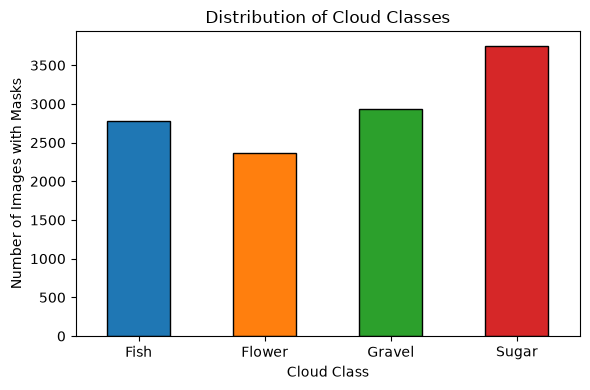

In [286]:
# Plot the distribution of cloud classes with a different color for each bar
import matplotlib.pyplot as plt

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

ax = mask_counts.plot(
    kind='bar',
    figsize=(6, 4),
    color=colors,
    edgecolor='black'
)

ax.set_title('Distribution of Cloud Classes')
ax.set_xlabel('Cloud Class')
ax.set_ylabel('Number of Images with Masks')
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

##### Number of labels per image:

In [287]:
# Identify rows where EncodedPixels contains a valid, non-null, non-empty mask
valid_mask = (
    train_df['EncodedPixels'].notna()
    & train_df['EncodedPixels'].astype(str).str.strip().ne('')
)

# Count the number of valid masks/classes for each image
labels_per_image = valid_mask.groupby(train_df['Image']).sum()
labels_per_image

Image
0011165.jpg    2
002be4f.jpg    3
0031ae9.jpg    3
0035239.jpg    2
003994e.jpg    3
              ..
ffcedf2.jpg    1
ffd11b6.jpg    2
ffd3dfb.jpg    1
ffd6680.jpg    2
ffea4f4.jpg    1
Name: EncodedPixels, Length: 5546, dtype: int64

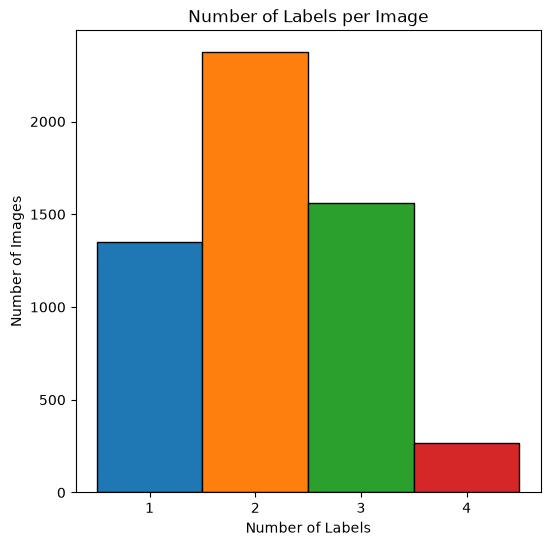

In [288]:
fig, ax = plt.subplots(figsize=(6, 6))

# Create one bin for each possible number of labels
counts, bins, patches = ax.hist(
    labels_per_image,
    bins=[0.5, 1.5, 2.5, 3.5, 4.5],
    edgecolor='black'
)

# Assign a different color to each histogram bar
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

for patch, color in zip(patches, colors):
    patch.set_facecolor(color)

ax.set_title('Number of Labels per Image')
ax.set_ylabel('Number of Images')
ax.set_xlabel('Number of Labels')
ax.set_xticks([1, 2, 3, 4])

plt.show()


#####  Correlation between different cloud types.

In [289]:
import pandas as pd

# Create dummy columns from the Class column
corr_df = pd.get_dummies(
    train_df,
    columns=['Class'],
    prefix='Label',
    dtype=int
)

# Identify rows containing a valid, non-empty segmentation mask
corr_df['HasMask'] = (
    corr_df['EncodedPixels'].notna()
    & corr_df['EncodedPixels'].astype(str).str.strip().ne('')
).astype(int)

# Keep a class value equal to 1 only when that class has a valid mask
cloud_classes = ['Fish', 'Flower', 'Gravel', 'Sugar']

for cloud_class in cloud_classes:
    column = f'Label_{cloud_class}'
    corr_df[column] = corr_df[column] * corr_df['HasMask']

corr_df.head()

,Image_Label,EncodedPixels,Image,Label_Fish,Label_Flower,Label_Gravel,Label_Sugar,HasMask
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,1,0,0,0,1
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,0,1,0,0,1
2,0011165.jpg_Gravel,,0011165.jpg,0,0,0,0,0
3,0011165.jpg_Sugar,,0011165.jpg,0,0,0,0,0
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,1,0,0,0,1


In [290]:
# transforms corr_df, which has four rows for each image, into a table with one row per image
import matplotlib.pyplot as plt
import seaborn as sns

# Cloud-class indicator columns
class_columns = [
    'Label_Fish',
    'Label_Flower',
    'Label_Gravel',
    'Label_Sugar'
]

# Combine the four rows of each image into one row
# max() returns 1 when the class has a valid mask in that image
class_presence = (
    corr_df.groupby('Image')[class_columns]
    .max()
)

# Rename the columns for cleaner plot labels
class_presence.columns = ['Fish', 'Flower', 'Gravel', 'Sugar']

In [291]:
class_presence

,Fish,Flower,Gravel,Sugar
Image,,,,
0011165.jpg,1,1,0,0
002be4f.jpg,1,1,0,1
0031ae9.jpg,1,1,0,1
0035239.jpg,0,1,1,0
003994e.jpg,1,0,1,1
...,...,...,...,...
ffcedf2.jpg,1,0,0,0
ffd11b6.jpg,0,1,0,1
ffd3dfb.jpg,0,0,0,1


            Fish    Flower    Gravel     Sugar
Fish    1.000000 -0.102750 -0.036661 -0.076238
Flower -0.102750  1.000000 -0.239079 -0.151605
Gravel -0.036661 -0.239079  1.000000  0.061175
Sugar  -0.076238 -0.151605  0.061175  1.000000


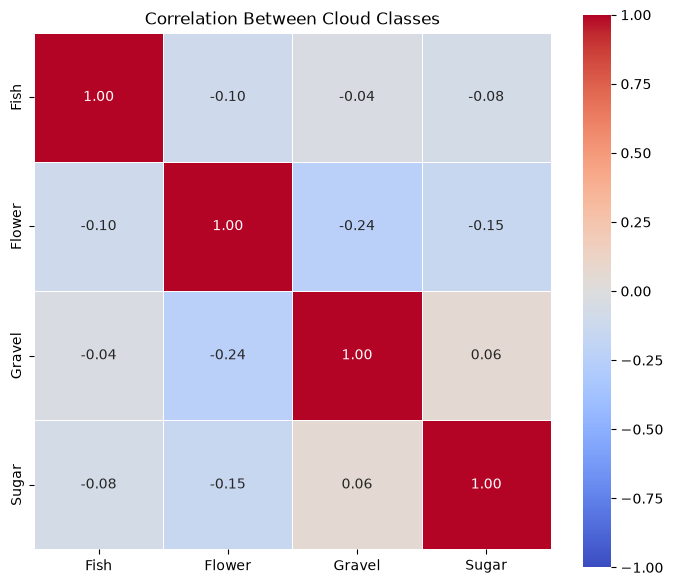

In [292]:
# Calculate correlations between cloud-class presence
correlation_matrix = class_presence.corr()

print(correlation_matrix)

# Plot the correlation heatmap
plt.figure(figsize=(7, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title('Correlation Between Cloud Classes')
plt.tight_layout()
plt.show()

##### Exploring the images

##### Image size (number of pixels in images)

In [293]:
# load dataframe with train labels

train_df = pd.read_csv(r"../data/raw/train.csv/train.csv")
train_df.head(15)

,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...
5,002be4f.jpg_Flower,100850 142 101234 142 101618 142 102002 142 10...
6,002be4f.jpg_Gravel,NaN
7,002be4f.jpg_Sugar,5074 96 5458 96 5842 96 6226 96 6610 96 6994 9...
8,0031ae9.jpg_Fish,579 190 963 190 1347 190 1731 190 2115 190 249...
9,0031ae9.jpg_Flower,178 193 562 193 946 193 1330 193 1714 193 2098...


In [294]:
# Split Image_Label into image name and class
train_df["Image"] = train_df["Image_Label"].apply(lambda x: x.split("_")[0])
train_df["Class"] = train_df["Image_Label"].apply(lambda x: x.split("_")[1])

In [295]:
def get_image_sizes(train = True):
    '''
    Function to get sizes of images from test and train sets.
    INPUT:
        train - indicates whether we are getting sizes of images from train or test set
    '''
    if train:
        path = train_path
    else:
        path = test_path
        
    widths = []
    heights = []
    
    images = sorted(glob(path + '*.jpg'))
    
    max_im = Image.open(images[0])
    min_im = Image.open(images[0])
        
    for im in range(0, len(images)):
        image = Image.open(images[im])
        width, height = image.size
        
        if len(widths) > 0:
            if width > max(widths):
                max_im = image

            if width < min(widths):
                min_im = image

        widths.append(width)
        heights.append(height)
        
    return widths, heights, max_im, min_im

In [296]:
# get sizes of images from test and train sets
train_widths, train_heights, max_train, min_train = get_image_sizes(train = True)
test_widths, test_heights, max_test, min_test = get_image_sizes(train = False)

# max_im is the image with the largest width.
# min_im is the image with the smallest width.

In [297]:
print('Maximum width for training set is {}'.format(max(train_widths)))
print('Minimum width for training set is {}'.format(min(train_widths)))
print('Maximum height for training set is {}'.format(max(train_heights)))
print('Minimum height for training set is {}'.format(min(train_heights)))

Maximum width for training set is 576
Minimum width for training set is 576
Maximum height for training set is 384
Minimum height for training set is 384


In [298]:
print('Maximum width for test set is {}'.format(max(test_widths)))
print('Minimum width for test set is {}'.format(min(test_widths)))
print('Maximum height for test set is {}'.format(max(test_heights)))
print('Minimum height for test set is {}'.format(min(test_heights)))

Maximum width for test set is 576
Minimum width for test set is 576
Maximum height for test set is 384
Minimum height for test set is 384


All of the train images have the same size. Moreover, all of the test images have the size.

##### Visualize sample train images

Visualizing trian images

In [299]:
# helper function to get a string of labels for the picture
def get_labels(image_id):
    ''' Function to get the labels for the image by name'''
    im_df = train_df[train_df['Image'] == image_id].fillna('-1')
    im_df = im_df[im_df['EncodedPixels'] != '-1'].groupby('Class').count()
    
    index = im_df.index
    all_labels = ['Fish', 'Flower', 'Gravel', 'Sugar']
    
    labels = ''
    
    for label in all_labels:
        if label in index:
            labels = labels + ' ' + label
    
    return labels

# function to plot a grid of images and their labels
def plot_training_images(width = 5, height = 2):
    """
    Function to plot grid with several examples of cloud images from train set.
    INPUT:
        width - number of images per row
        height - number of rows

    OUTPUT: None
    """
    
    # get a list of images from training set
    images = sorted(glob(train_path + '*.jpg'))
    
    fig, axs = plt.subplots(height, width, figsize=(width * 3, height * 3))
    # create a list of random indices 
    rnd_indices = rnd_indices = [np.random.choice(range(0, len(images))) for i in range(height * width)]
    
    for im in range(0, height * width):
        # open image with a random index
        image_path = images[rnd_indices[im]]
        image = Image.open(images[rnd_indices[im]])
        
        i = im // width
        j = im % width

        # Extract only the filename, e.g. "0011165.jpg"
        image_name = Path(image_path).name
        
        # plot the image
        axs[i,j].imshow(image) #plot the data
        axs[i,j].axis('off')
        axs[i, j].set_title(get_labels(image_name))

    # set suptitle
    plt.suptitle('Sample images from the train set')
    plt.show()  

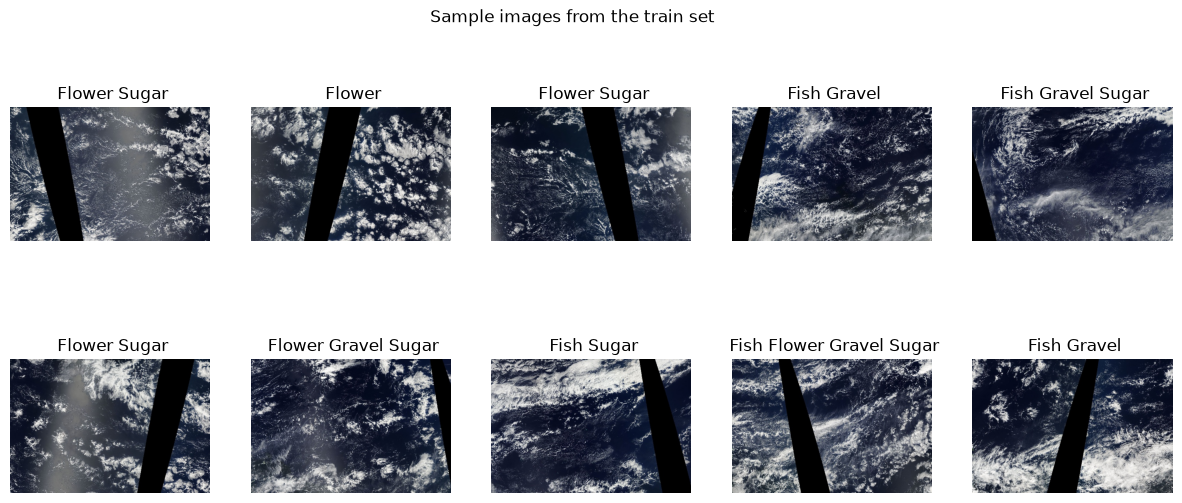

In [300]:
plot_training_images()

This plot shows **10 randomly selected training images**. The title above each image lists the cloud classes annotated in that image, such as `Gravel`, `Fish Gravel`, or `Gravel Sugar`.

It highlights that:

* One image can contain multiple cloud classes, so this is a **multi-label segmentation dataset**.
* `Gravel` and `Sugar` appear frequently in this sample.
* The black diagonal regions are missing or invalid satellite-image areas, not cloud classes.
* Because the images are randomly selected, rerunning `plot_training_images()` may display a different sample.


Visualizing train images with their cloud masks

In [301]:

from PIL import Image
from imgaug.augmentables.segmaps import SegmentationMapsOnImage


def rle_to_mask(rle_string, width, height):
    """
    Convert an RLE string into a binary segmentation mask.
    """

    # Return an empty mask when no RLE value exists
    if rle_string in ("", "-1", -1, None):
        return np.zeros((height, width), dtype=np.uint8)

    # Convert the RLE string into integer pairs
    rle_numbers = [int(value) for value in rle_string.split()]
    rle_pairs = np.array(rle_numbers).reshape(-1, 2)

    # Create an empty flattened mask
    mask = np.zeros(height * width, dtype=np.uint8)

    # Fill the cloud pixels
    for start_index, length in rle_pairs:
        start_index -= 1
        mask[start_index:start_index + length] = 1

    # Reshape using the column-major RLE arrangement
    return mask.reshape((height, width), order="F")


def get_mask(line_id, shape=(1400, 2100)):
    """
    Get the mask belonging to one row of train_df.

    shape is given as:
    (height, width)
    """

    # Select the row by its position
    row = train_df.iloc[line_id]

    # Read its encoded mask
    rle = row["EncodedPixels"]

    # Decode and return the mask
    return rle_to_mask(
        rle_string=rle,
        width=shape[1],
        height=shape[0]
    )


def visualize_image_with_mask(line_id):
    """
    Display an image with its cloud-class mask.
    """

    # Select the requested row
    row = train_df.iloc[line_id]

    # Open the corresponding image
    image_path = Path(train_path) / row["Image"]
    image = np.asarray(Image.open(image_path).convert("RGB"))

    # Create the mask using the image's actual dimensions
    mask = rle_to_mask(
        rle_string=row["EncodedPixels"],
        width=image.shape[1],
        height=image.shape[0]
    )

    # Create an imgaug segmentation map
    segmap = SegmentationMapsOnImage(
        mask.astype(np.int32),
        shape=image.shape
    )

    # Draw the mask over the image
    image_with_mask = segmap.draw_on_image(
        image,
        alpha=0.5
    )

    # imgaug may return a list containing the image
    if isinstance(image_with_mask, list):
        image_with_mask = image_with_mask[0]

    # Display the result
    plt.figure(figsize=(12, 6))
    plt.imshow(image_with_mask)
    plt.title(f'Cloud class: {row["Class"]}')
    plt.axis("off")
    plt.show()

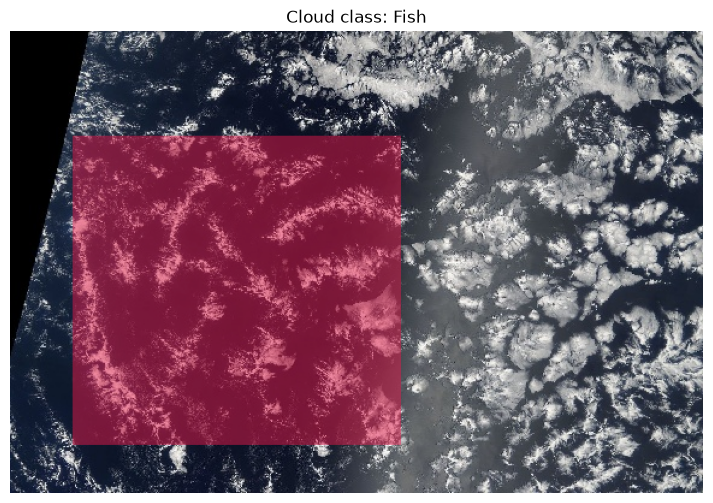

In [302]:
visualize_image_with_mask(0)

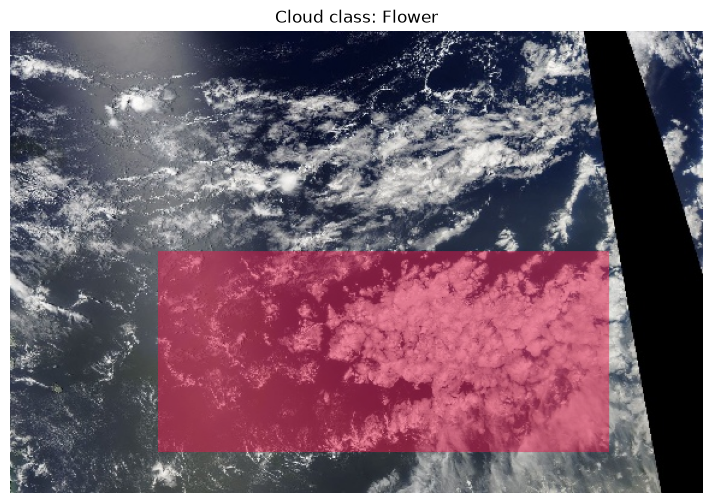

In [303]:
visualize_image_with_mask(89)

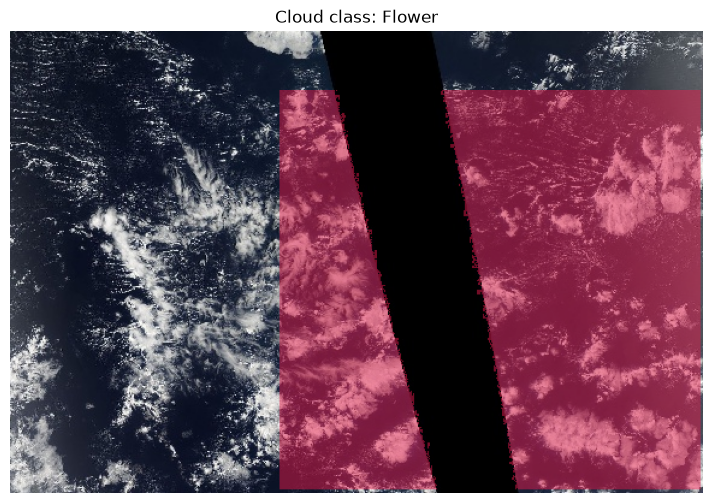

In [304]:
visualize_image_with_mask(501)

Visualize image grids (multiple training images and their masks):

In [306]:
def plot_training_images_and_masks(n_images=3):
    """Plot random images with their segmentation masks."""

    images = sorted(glob(train_path + "*.jpg"))

    fig, ax = plt.subplots(n_images, 4, figsize=(20, 4 * n_images))

    # Necessary when n_images=1
    ax = np.atleast_2d(ax)

    rnd_indices = [
        np.random.choice(range(len(images)))
        for _ in range(n_images)
    ]

    for im in range(n_images):

        # Define the path inside the loop
        image_path = images[rnd_indices[im]]

        image = Image.open(image_path).convert("RGB")
        image_array = np.asarray(image)
        shape = image_array.shape[:2]

        # Get the four masks
        fish = get_mask_by_image_id(
            image_path, "Fish", shape
        )

        flower = get_mask_by_image_id(
            image_path, "Flower", shape
        )

        gravel = get_mask_by_image_id(
            image_path, "Gravel", shape
        )

        sugar = get_mask_by_image_id(
            image_path, "Sugar", shape
        )

        masks = [fish, flower, gravel, sugar]
        classes = ["Fish", "Flower", "Gravel", "Sugar"]

        for column, (mask, class_name) in enumerate(
            zip(masks, classes)
        ):
            if np.sum(mask) > 0:
                segmap = SegmentationMapOnImage(
                    mask,
                    shape=shape,
                    nb_classes=2
                )

                displayed_image = np.array(
                    segmap.draw_on_image(image_array)
                ).reshape(image_array.shape)

                title = class_name
            else:
                displayed_image = image_array
                title = f"{class_name} — no mask"

            ax[im, column].imshow(displayed_image)
            ax[im, column].axis("off")
            ax[im, column].set_title(title)

    plt.suptitle("Sample images and masks from the train set")
    plt.tight_layout()
    plt.show()

c:\Users\mahsa\Desktop\cloud_segmentation_project\cloud_segmentation_repo\jun26_bcds_cloud_segmentation\cloudenvpy312\Lib\site-packages\imgaug\imgaug.py:184: DeprecationWarning: Function `SegmentationMapOnImage()` is deprecated. Use `SegmentationMapsOnImage` instead. (Note the plural 'Maps' instead of old 'Map'.).
  warn_deprecated(msg, stacklevel=3)
c:\Users\mahsa\Desktop\cloud_segmentation_project\cloud_segmentation_repo\jun26_bcds_cloud_segmentation\cloudenvpy312\Lib\site-packages\imgaug\imgaug.py:106: DeprecationWarning: Providing nb_classes to SegmentationMapsOnImage is no longer necessary and hence deprecated. The argument is ignored and can be safely removed.
  warn(msg, category=DeprecationWarning, stacklevel=stacklevel)


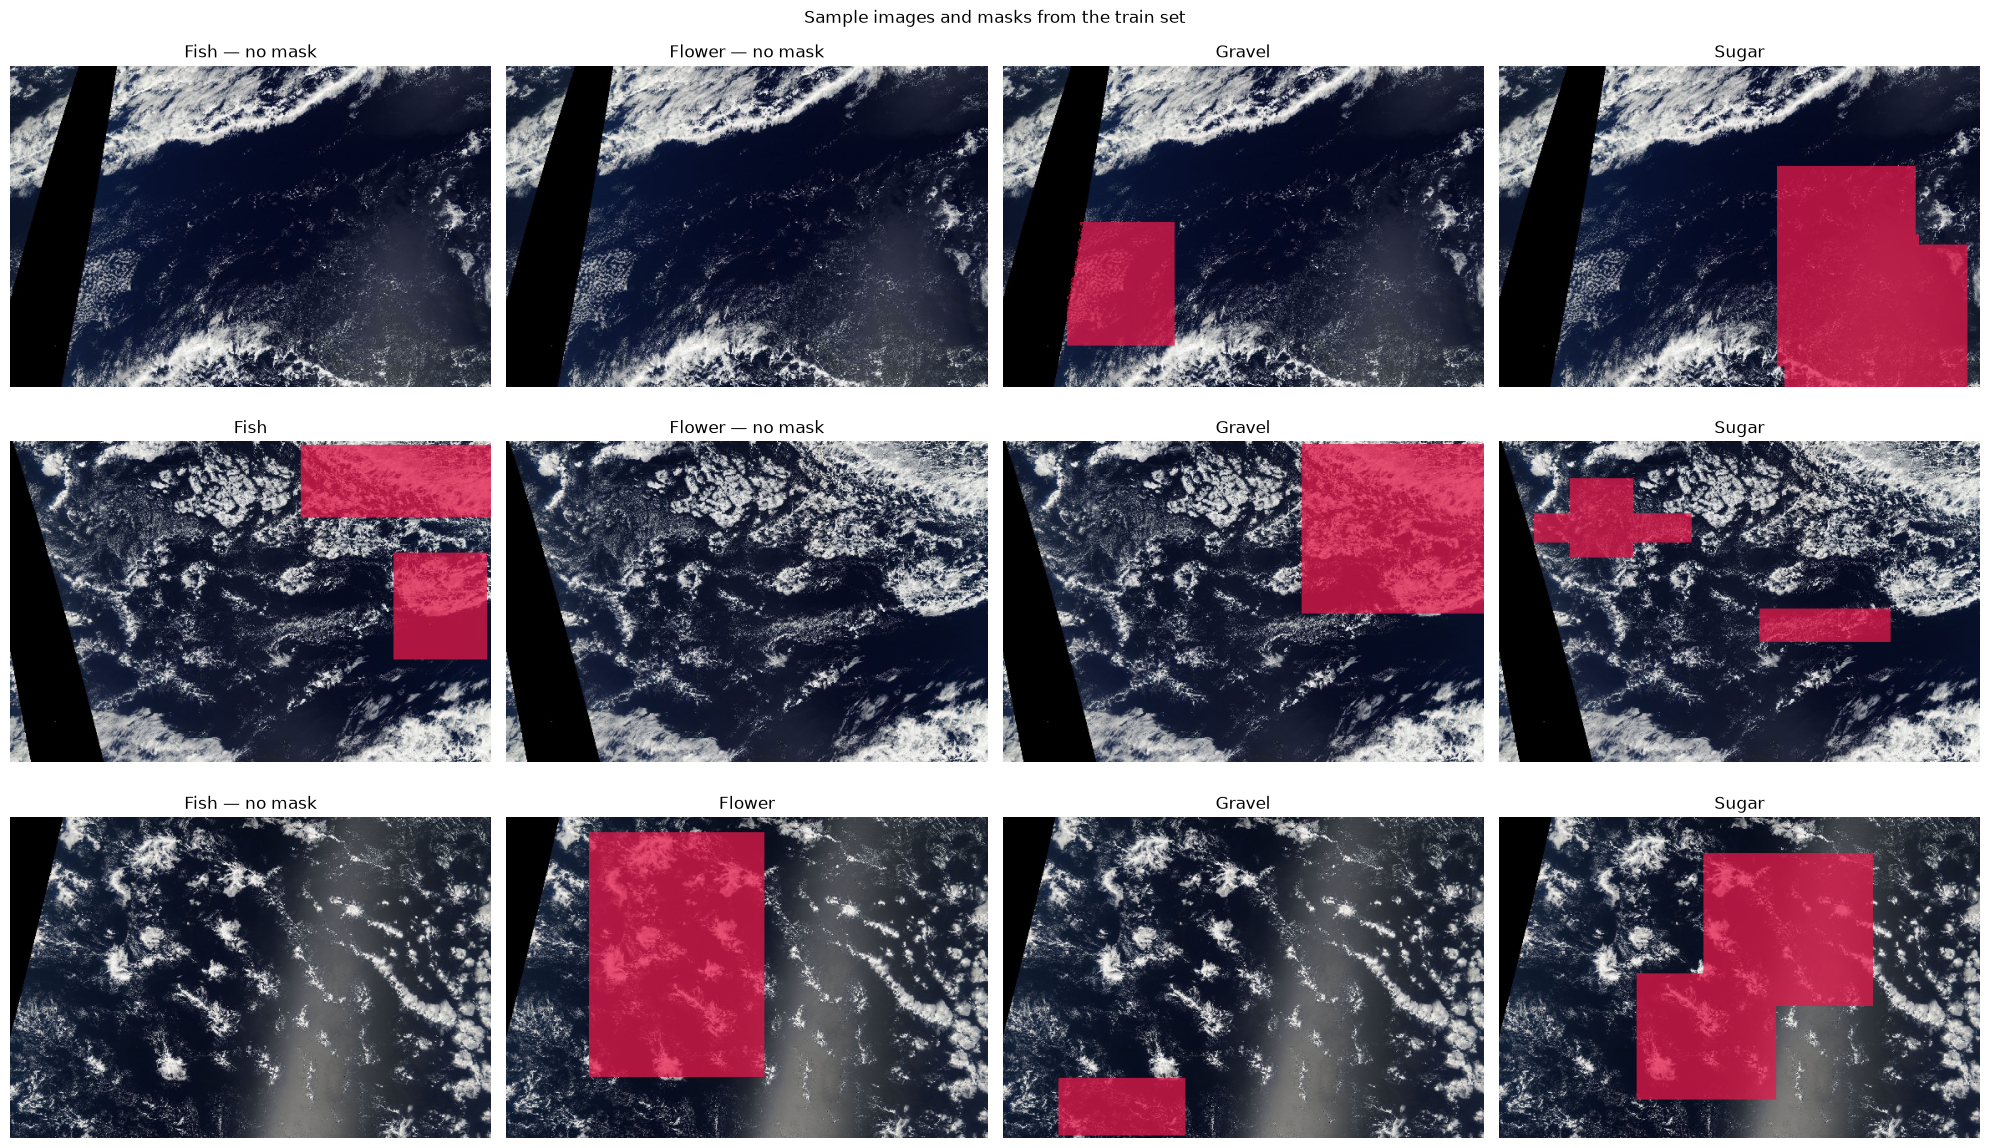

In [307]:
plot_training_images_and_masks(n_images=3)

Image and mask augmetation 

In [308]:
# initialize augmentations
seq = iaa.Sequential([
    iaa.Affine(rotate=(-30, 30)),
    iaa.Fliplr(0.5),
    iaa.ElasticTransformation(alpha=10, sigma=1)
])

# generate random index for an image
rnd_index = np.random.choice(range(len(train_fns)))
img_id = train_fns[rnd_index]

image = Image.open(img_id)
segmap = create_segmap(img_id)

# apply augmentation for image and mask
image_aug, segmap_aug = seq(image=np.asarray(image), segmentation_maps=segmap)

# visualize the image and map
side_by_side = np.hstack([
    draw_segmentation_maps(img_id),
    np.asarray(segmap_aug.draw_on_image(image_aug)).reshape(np.asarray(image).shape)
])

labels = get_labels(img_id.split('/')[-1])

fig, ax = plt.subplots(figsize=(15, 7))
ax.axis('off')
plt.title('Segmentation maps (original and augmented image):' + labels)
plt.legend()

ax.imshow(side_by_side)

NameError: name 'create_segmap' is not defined

Distribution of claud masks

In [ ]:
def add_mask_areas(df):
    """
    Add a MaskArea column containing the number of pixels
    belonging to each cloud mask.
    """

    # Create a copy so the original DataFrame is not modified
    result = df.copy()

    def calculate_mask_area(rle):
        # Missing or empty RLE means that no mask is present
        if pd.isna(rle) or rle == "":
            return 0

        # Convert the RLE string into integers
        numbers = [int(value) for value in rle.split()]

        # Run lengths are stored at positions 1, 3, 5, ...
        lengths = numbers[1::2]

        # Total number of mask pixels
        return sum(lengths)

    result["MaskArea"] = result["EncodedPixels"].apply(
        calculate_mask_area
    )

    return result

In [ ]:
masks_df = add_mask_areas(train_df)

In [ ]:
masks_df

,Image_Label,EncodedPixels,Image,Class,MaskArea
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,Fish,70161
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,Flower,87006
2,0011165.jpg_Gravel,,0011165.jpg,Gravel,0
3,0011165.jpg_Sugar,,0011165.jpg,Sugar,0
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,Fish,126750
...,...,...,...,...,...
22179,ffd6680.jpg_Sugar,,ffd6680.jpg,Sugar,0
22180,ffea4f4.jpg_Fish,,ffea4f4.jpg,Fish,0
22181,ffea4f4.jpg_Flower,90038 185 90422 185 90806 185 91190 185 91574 ...,ffea4f4.jpg,Flower,49274
22182,ffea4f4.jpg_Gravel,,ffea4f4.jpg,Gravel,0


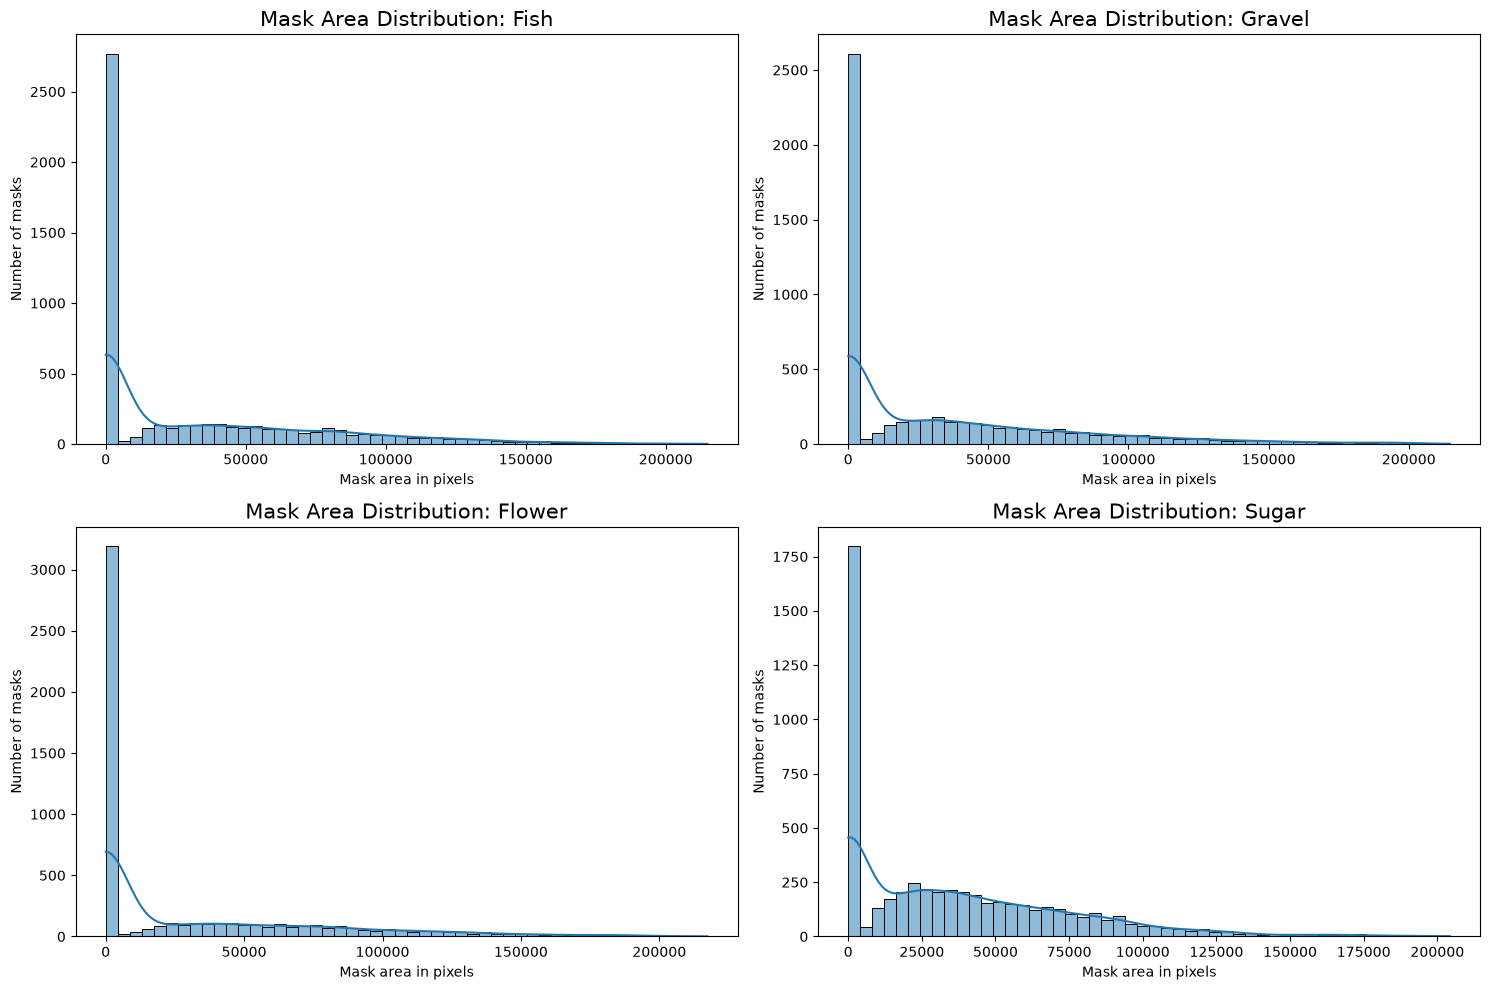

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


# Cloud classes to visualize
cloud_classes = ["Fish", "Gravel", "Flower", "Sugar"]

# Create one figure containing four plots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Flatten the 2×2 axes array so it is easier to loop through
axes = axes.ravel()

for ax, cloud_class in zip(axes, cloud_classes):

    # Select mask areas belonging to the current cloud class
    mask_areas = masks_df.loc[
        masks_df["Class"] == cloud_class,
        "MaskArea"
    ]

    # Plot histogram and KDE curve
    sns.histplot(
        mask_areas,
        bins=50,
        kde=True,
        ax=ax
    )

    ax.set_title(
        f"Mask Area Distribution: {cloud_class}",
        fontsize=15
    )
    ax.set_xlabel("Mask area in pixels")
    ax.set_ylabel("Number of masks")


plt.tight_layout()
plt.show()

All four cloud classes have right-skewed distributions:

Many rows have MaskArea = 0, meaning no mask is present.
Most existing masks are relatively small or medium-sized.
Only a few masks are very large.

Differences:

Fish: many medium and large masks; some exceed 200,000 pixels.
Gravel: mostly smaller masks, with fewer very large ones.
Flower: similar to Fish, with many zero values and some large masks.
Sugar: has fewer zero values and more masks around 20,000–80,000 pixels.

Overall, Fish and Flower tend to have larger masks, while Gravel masks are generally smaller. Sugar has the most visible concentration of medium-sized masks.